# Hybridization and Scar Plots in Multi-Mode Quantum Circuits

This tutorial demonstrates how to model multi-mode superconducting circuits in **QBrAn** and use the **hybridization metric** $\Theta$ to identify multi-photon resonances.

We replicate key experimental and simulations findings from Dai et al. (2026), investigating drive-induced transitions between a transmon qubit and an auxiliary (spectator) resonator mode.

---

## 1. Multi-Mode Circuit Hamiltonian

Consider a transmon coupled capacitively to a harmonic spectator resonator mode. The joint undriven Hamiltonian is:
$$\hat{H}_0 = 4 E_C (\hat{n}_t - n_g)^2 - E_J \cos\hat{\varphi}_t + \omega_r \hat{a}^\dagger \hat{a} + g (\hat{n}_t - n_g)(\hat{a} + \hat{a}^\dagger)$$

where:
* $E_J$ and $E_C$ are the Josephson and charging energies of the transmon,
* $\hat{n}_t$ and $\hat{\varphi}_t$ are the transmon Cooper-pair number and phase operators satisfying $[\hat{\varphi}_t, \hat{n}_t] = i$,
* $\omega_r$ is the bare angular frequency of the spectator resonator,
* $\hat{a}^\dagger, \hat{a}$ are the creation and annihilation operators of the resonator mode,
* $g$ is the capacitive coupling rate between the transmon charge and resonator voltage quadrature.

### Driven Circuit Dynamics and Multi-Photon Scattering
When applying a microwave tone to the transmon $\hat{H}_d(t) = \Omega_d \cos(\omega_d t) \, \hat{n}_t$, the drive dresses the circuit eigenstates via power-dependent AC Stark shifts. At specific combinations of drive frequency and power, the system satisfies energy-matching conditions for **multi-photon scattering processes** $m \, \omega_d \approx (E_{t, n'} - E_{t, n}) + k \, \omega_r$. Here, $m$ drive photons are absorbed (or emitted) to simultaneously induce an $n \to n'$ transition in the transmon and create $k$ excitations in the spectator resonator mode.

In [5]:
import qbran as br

import numpy as np
import matplotlib.pyplot as plt

# Circuit definition
# Transmon qubit (tmon) coupled to a spurious resonator mode (res)
# Parameter from Dai et al. Phys. Rev. X 16, 011011 (2026)
tmon = br.Transmon(EJ=16.40, EC=0.1695, ng=0.0, truncated_dim=20, name="tmon")
res = br.Resonator(E_osc=9.029, truncated_dim=3, name="res")
circuit = br.HilbertSpace([tmon, res])
circuit.add_interaction(tmon, res, g=0.153) # Capacitive coupling

# Drive parameters
freq_drive = 10.7282
amp_drive  = np.linspace(0, 3.0, 150)

## 2. Multi-Photon Resonances and the Hybridization Metric $\Theta$

In this simulation, we analyze the resonant conversion between the qubit first excited state $|1, 0\rangle$ and the multi-mode state $|4, 1\rangle$ (transmon in level 4, resonator in level 1): $|1, 0\rangle \longleftrightarrow |4, 1\rangle$. This transition is mediated by the absorption of two drive photons.

### Detecting Resonances: Why Bare Overlap Fails
Ordinarily, one might attempt to detect resonances by tracking the bare state overlap $|\langle i | \phi_k(\Omega_d) \rangle|^2$. However, as drive power increases, the drive non-resonantly dresses (displaces) the state even far away from any avoided crossing. This causes bare overlap to monotonically decay, obscuring true resonant avoided crossings.

To isolate true resonances without interference from dispersive background shifts, the library adopts the **hybridization metric** $\Theta$ introduced by Xiao et al. (2025) and D. Weiss:

1. **Dispersive Background Fitting**:
   Over regions where the system is off-resonance (overlap >`overlap_cutoff`), QBrAn fits a smooth 2D polynomial in $(\omega_d, \Omega_d)$ to the Floquet eigenvectors. This constructs an **ideal non-resonant reference state** $|\phi_k^{\text{ideal}}(\omega_d, \Omega_d)\rangle$ that tracks the continuous dispersive shift.
2. **Resonance Masking**:
   Any data points where the overlap drops below `overlap_cutoff` are flagged as active resonance zones and excluded from the polynomial regression.
3. **Iterative Amplitude Windowing (`fit_range_fraction`)**:
   For broad amplitude sweeps where the displacement is strongly non-linear, QBrAn divides the amplitude axis into piecewise windows, updating the reference baseline across windows to avoid polynomial divergence.
4. **Hybridization Definition**:
   The hybridization metric is defined as:
   $$\Theta_k = 1 - |\langle \phi_k^{\text{ideal}} | \phi_k \rangle|^2$$
   * **Off-resonance**: The Floquet mode matches the ideal displaced state, yielding $\Theta_k \approx 0$.
   * **At an avoided crossing**: When two levels undergo a 50:50 avoided crossing, $|\langle \phi_k^{\text{ideal}} | \phi_k \rangle|^2 = 0.5$, producing a peak of $\Theta_k = 0.5$.


In [6]:
# State to track in the hybridization analysis
tracking = [
    circuit.state_to_index(0, 0), # |0,0>
    circuit.state_to_index(1, 0), # |1,0>
    circuit.state_to_index(4, 1), # |4,1>
]

opt = br.Options(
    tracked_states=tracking, 
    hybridization="fit", 
    fit_cutoff=2,           # Maximum polynomial order for hybridization fitting
    overlap_cutoff=0.5,     # Minimum overlap threshold for resonance masking in hybridization fitting
    fit_range_fraction=0.5  # Tterative fitting window
)
analysis = circuit.branch_analysis(kind="propagator", options=opt)
reslts = analysis.run(freq_drive, amp_drive)

Branch Analysis: 100%|██████████| 1/1 [00:00<00:00,  1.56it/s]


### Dimensionless Drive Parameter $\xi$ and AC Stark Shift
Following the convention of Dai et al., the drive strength is parameterized by the dimensionless displacement parameter $\xi$:
$$\xi = \frac{2 \, n_{\text{zpf}} \, \omega_d \, \Omega_d}{\omega_d^2 - \omega_{01}^2}$$

where $n_{\text{zpf}}$ represents the transmon charge zero-point fluctuations. In the weakly driven dispersive regime, $\xi^2$ scales linearly with the drive power and induces a leading-order transmon AC Stark shift $\Delta_{\text{Stark}} \approx \xi^2 \, \alpha_q/2$, where $\alpha_q = \omega_{12} - \omega_{01}$ is the transmon anharmonicity.

In [7]:
def AmpToXi(amp, freq):
    """Dimensionless drive amplitude from Dai et al."""
    nzpf = (tmon.EJ/(32 * tmon.EC))**(1/4)
    return (2* nzpf * freq * amp) / (freq**2 - tmon.E01**2)

# Compute AC-Stark shift from the drive amplitude
xi = AmpToXi(amp_drive, freq_drive)
ac_stark = xi**2 * tmon.anharmonicity / 2

avg_excitation = reslts.avg_excitation[0, :, :]
hybridization  = np.clip(reslts.hybridization[0, :, :], 0, 0.5)

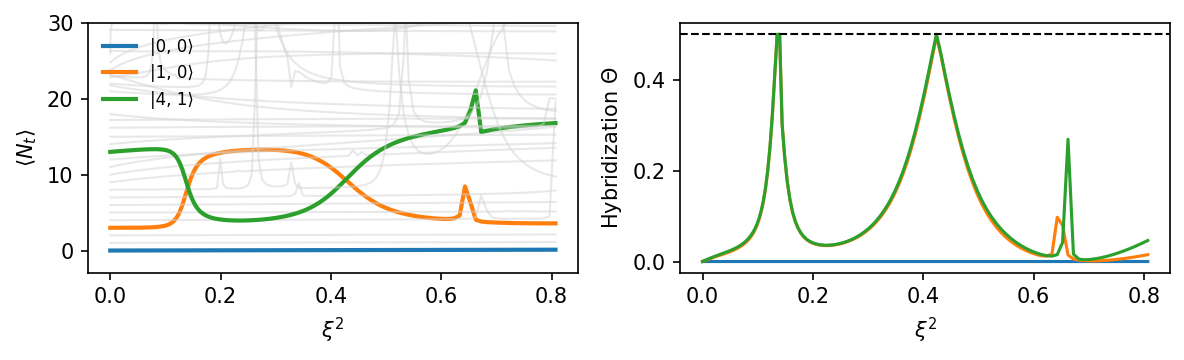

In [8]:
colored = tracking

fig, axs = plt.subplots(1, 2, figsize=(8, 2.5), dpi=150)

for i in range(avg_excitation.shape[1]):
    col = f'C{colored.index(i)}' if i in colored else 'lightgray'
    legend = circuit.state_label(i) if i in colored else None
    alp = 1.0 if i in colored else 0.5
    lw  = 2.0 if i in colored else 1.0
    axs[0].plot(xi**2, avg_excitation[:, i], color=col, alpha=alp, linewidth=lw, label=legend)
axs[0].set_ylim(None, 30)
axs[0].legend(loc='upper left', fontsize=8, frameon=False)

for i, _ in enumerate(colored):
    axs[1].plot(xi**2, hybridization[:, i])
axs[1].axhline(0.5, color='k', ls='--', lw=1)
for i in [0,1]: axs[i].set_xlabel(r'$\xi^2$')
axs[0].set_ylabel(r'$\langle N_t \rangle$')
axs[1].set_ylabel(r'Hybridization $\Theta$')

fig.tight_layout()
plt.show()

## 3. Branch Swapping and 2D "Scar" Resonance Landscapes

By sweeping across both drive frequency $\omega_d$ and drive power $\xi^2\propto\Omega_d$, we can map out every multi-photon resonance that intersects the operational subspace:
* Each resonance condition $m \, \omega_d \approx \Delta E(\xi)$ traces a curved line in the $(\omega_d, \xi^2)$ plane due to power-dependent AC Stark level shifts.
* Visualizing the hybridization $\Theta(\omega_d, \xi^2)$ as a 2D heatmap highlights these narrow resonance channels, often called in literature *scar*.
* In superconducting circuit literature, these 2D resonance plots are termed **scar plots** or **stability maps**. They provide an exhaustive fingerprint of:

In [ ]:
# Parameters from Dai et al. Phys. Rev. X 16, 011011 (2026)
freq_drive_grid = np.linspace(10.2, 11.4, 400)
amp_drive_grid  = np.linspace(0, 5.2, 200)

# We track the ground and the first excited
tracking_grid = [
    circuit.state_to_index(0, 0), # |0,0>
    circuit.state_to_index(1, 0), # |1,0>
]
opt = br.Options(tracked_states=tracking_grid)

analysis_grid = circuit.branch_analysis(kind="propagator", options=opt)
res_grid = analysis_grid.run(freq_drive_grid, amp_drive_grid)

Branch Analysis: 100%|██████████| 400/400 [05:44<00:00,  1.16it/s]


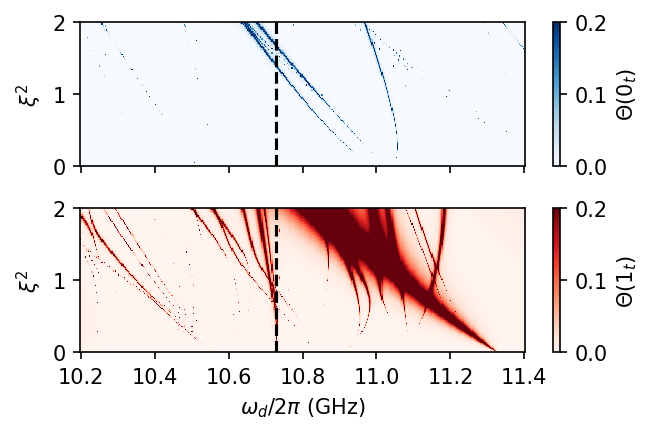

In [62]:
xi_grid = AmpToXi(amp_drive_grid[:, None], freq_drive_grid[None, :])
hybr_g = np.clip(res_grid.hybridization[:, :, 0], 0, 0.5)
hybr_e = np.clip(res_grid.hybridization[:, :, 1], 0, 0.5)

fig, axs = plt.subplots(2, 1, figsize=(4.5, 3), dpi=150, sharex=True)
axs[0].pcolormesh(freq_drive_grid, xi_grid**2, hybr_g.T, shading='auto', cmap='Blues', vmin=0, vmax=0.2)
axs[1].pcolormesh(freq_drive_grid, xi_grid**2, hybr_e.T, shading='auto', cmap='Reds', vmin=0, vmax=0.2)
for i in [0,1]:
    axs[i].axvline(freq_drive, color='k', ls='--', lw=1.5) 
    axs[i].set_ylabel(r'$\xi^2$')
    axs[i].set_ylim(0.0, 2.0)
axs[1].set_xlabel(r'$\omega_d/2\pi$ (GHz)')
fig.colorbar(axs[0].collections[0], ax=axs[0], location='right', label=r'$\Theta(0_t)$')
fig.colorbar(axs[1].collections[0], ax=axs[1], location='right', label=r'$\Theta(1_t)$')
fig.tight_layout()
plt.show()

## 4. References

1. **Multi-Mode Resonances**:
   * W. Dai, S. Hazra, D. K. Weiss, P. D. Kurilovich, T. Connolly, H. K. Babla, S. Singh, V. R. Joshi, A. Z. Ding, P. D. Parakh, J. Venkatraman, X. Xiao, L. Frunzio, and M. H. Devoret, *"Characterization of Drive-Induced Unwanted State Transitions in Superconducting Circuits"*, [Phys. Rev. X **16**, 011011 (2026)](https://doi.org/10.1103/zdpg-mhpc) (arXiv:2506.24070).
2. **Diagrammatic Effective Hamiltonian & Hybridization Fitting**:
   * X. Xiao, J. Venkatraman, R. G. Cortiñas, S. Chowdhury, and M. H. Devoret, *"A diagrammatic method to compute the effective Hamiltonian of driven nonlinear oscillators"*, [Phys. Rev. A **24**, 044026 (2025)](https://doi.org/10.1103/d6j2-lsf7) (arXiv:2304.13656).
   * D. K. Weiss, *"Floquet: Identifying nonlinear resonances in quantum systems due to parametric drives"*, GitHub repository: [dkweiss31/floquet](https://github.com/dkweiss31/floquet).
3. **Transmon Ionization**:
   * M. F. Dumas, et al., *"Measurement-induced transmon ionization"*, [Phys. Rev. X **14**, 041023 (2024)](https://doi.org/10.1103/PhysRevX.14.041023).
   * R. Shillito, et al., *"Dynamics of transmon ionization"*, [Phys. Rev. A **18**, 034031 (2022)](https://doi.org/10.1103/PhysRevApplied.18.034031).